# Human Plasma protocol — dramp

One source and condition; read the compact normalized contract and export that same contract.

In [1]:
DATA_SOURCE = "dramp"
CONDITION = "human_plasma"
WRITE_EXPORTS = True
NOTEBOOK_ID = "protocol_human_plasma_dramp"
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
here = Path.cwd().resolve()
ROOT = next(p for p in [here, *here.parents] if (p / "src/pep_compass").is_dir())
sys.path.insert(0, str(ROOT / "assets/tools/proteolysis_data_manager/src"))
from proteolysis_data_manager.protocols.half_life.filtering import load_half_life_data, prepare_protocol, export_protocol
from proteolysis_data_manager.integration.half_life.schema import CLEAN_COLUMNS, source_mask, row_key, typed
from proteolysis_data_manager.analysis.half_life.visualization import (formatted_table, duration_summary, plot_duration_distributions,
    plot_acceptance_conditions, plot_before_after, readable_time_axis, time_bins, DURATION_COLORS, DURATION_LABELS)
DATA_ROOT = ROOT / "data/half_time_datasets"
SERIES = ROOT / "assets/experiments/analysis/09_26/20_serum_proteolysis_calibration_max/notebooks/0_data_analysis_half_life"
RESULTS = SERIES.parents[1] / "results/0_data_analysis_half_life" / CONDITION / NOTEBOOK_ID
if WRITE_EXPORTS: RESULTS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi":110, "axes.spines.top":False, "axes.spines.right":False, "axes.grid":True, "grid.alpha":.12})
def table(frame):
    if len(frame)>30: display(HTML(f"<p>Preview: 30 of {len(frame)} rows.</p>"))
    display(HTML(formatted_table(frame, limit=30)))
def figure(fig, name):
    if WRITE_EXPORTS: fig.savefig(RESULTS / name, bbox_inches="tight")
    plt.show(); plt.close(fig)
def counts(frame):
    point=frame.half_life_seconds.notna()
    return {"observations":len(frame), "sequences":frame.sequence.nunique(), "numeric":int(point.sum()),
            "class_only":int((~point & frame.half_life_class.notna()).sum()),
            "unresolved":int((~point & frame.half_life_class.isna()).sum())}

data = load_half_life_data(DATA_ROOT, DATA_SOURCE)
all_sources = load_half_life_data(DATA_ROOT)


## References, input coverage and missingness

The selected group, acceptance intervals and physiological reference assumptions are explicit below. Missing pH/temperature use reference values **only for the acceptance decision**. Reported columns stay null in exports. Serum/plasma fraction and peptide concentration are modeling parameters, not acceptance gates.

The 37 °C assay reference and human-serum baseline come from [Cavaco](https://pmc.ncbi.nlm.nih.gov/articles/PMC8301568/); pH 7.4 is the approved protocol reference, not an inferred source measurement.

Group key: {"in_vivo_in_vitro": "in vitro", "matrix": "plasma", "species": "human"}
Reference assumptions: {"ph": 7.4, "temperature_c": 37.0}
Acceptance bounds: {"ph": [7.35, 7.45], "temperature_c": [36, 38]}


scope,observations,sequences,numeric,class_only,unresolved
Complete normalized source,111,81,55,6,50
Selected group,5,1,1,0,4


field,documented,missing,denominator
ph,0,5,5
temperature_c,0,5,5
matrix_fraction,0,5,5
peptide_concentration_um,0,5,5
half_life_seconds,1,4,5
half_life_class,1,4,5
sd_seconds,0,5,5
ci_lower_seconds,0,5,5
ci_upper_seconds,0,5,5
ci_level,0,5,5


duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records
unresolved,no unique interval,4,0,4
short,<30 min,1,1,0
medium,30 min–6 h,0,0,0
long,>6 h,0,0,0


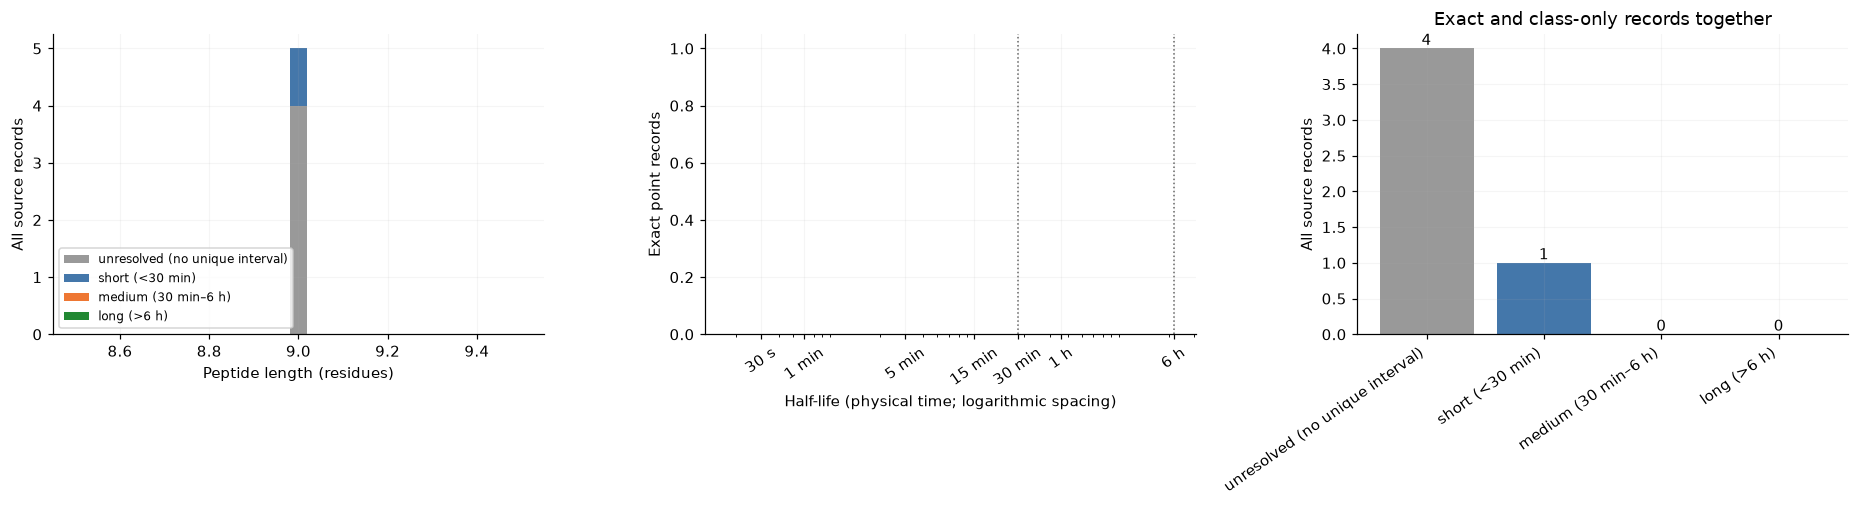

In [2]:
CONFIG = json.loads((SERIES / "protocols/protocol_config.json").read_text())
CONFIG["group"]["species"], CONFIG["group"]["matrix"] = CONDITION.split("_",1)
print("Group key:", json.dumps(CONFIG["group"],sort_keys=True))
print("Reference assumptions:", json.dumps(CONFIG["defaults"],sort_keys=True))
print("Acceptance bounds:", json.dumps(CONFIG["acceptance_bounds"],sort_keys=True))
rows = prepare_protocol(data, CONFIG)
table(pd.DataFrame([{"scope":"Complete normalized source", **counts(data)}, {"scope":"Selected group", **counts(rows)}]))
fields=["ph","temperature_c","matrix_fraction","peptide_concentration_um","half_life_seconds","half_life_class","sd_seconds","ci_lower_seconds","ci_upper_seconds","ci_level","replicate_count"]
table(pd.DataFrame([{"field":f,"documented":int(rows[f].notna().sum()),"missing":int(rows[f].isna().sum()),"denominator":len(rows)} for f in fields]))
table(duration_summary(rows))
figure(plot_duration_distributions(rows), "input_distributions.png")

## Acceptance conditions: pH and temperature

Each parameter has **one plot**. Blue bars are reported values; gray bars are missing values placed at the approved reference solely for filtering. The green band is the acceptance interval; the dashed line is the reference. The tables state exactly how many observations are rejected and why.

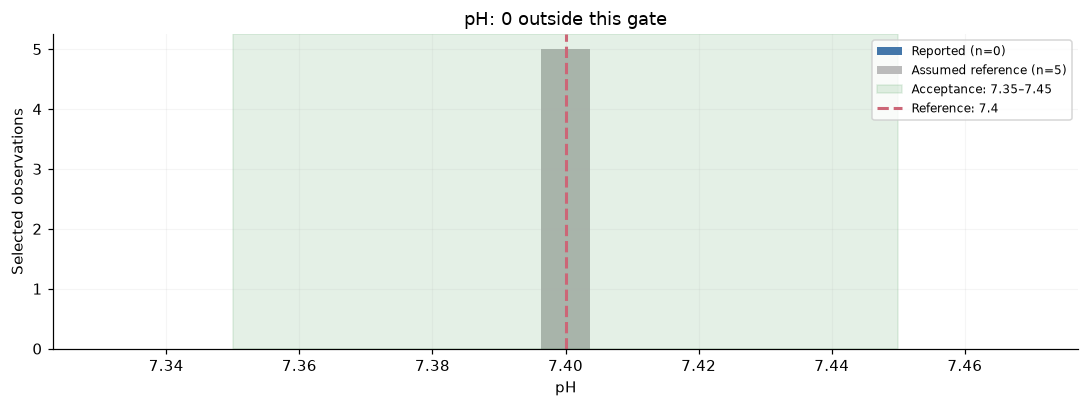

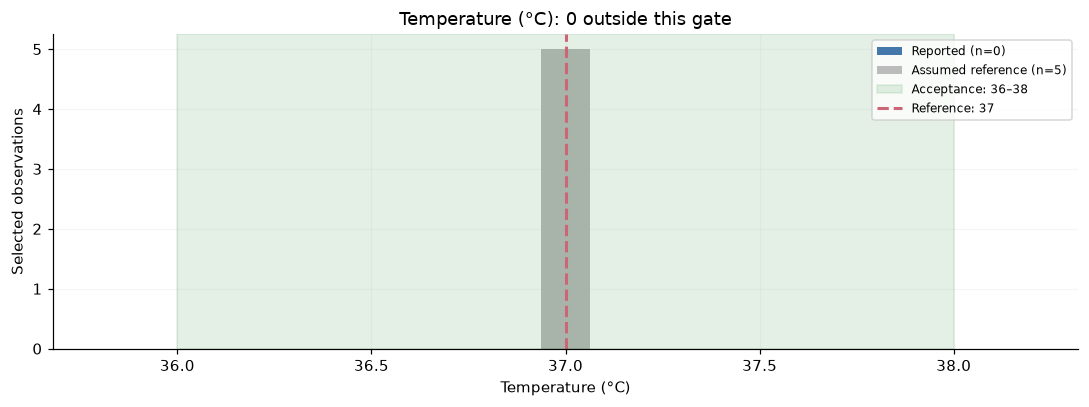

ph_origin,temperature_c_origin,condition_status,observations
assumed_reference,assumed_reference,accepted,5


Rejected by pH/temperature: 0 of 5


source_record_id,ph,ph_effective,temperature_c,temperature_c_effective,condition_status


In [3]:
for field, fig in plot_acceptance_conditions(rows, CONFIG).items():
    figure(fig, "acceptance_" + field + ".png")
table(rows.groupby(["ph_origin","temperature_c_origin","condition_status"],dropna=False).size().rename("observations").reset_index())
rejected = rows.loc[~rows.aggregation_eligible]
print("Rejected by pH/temperature:",len(rejected),"of",len(rows))
table(rejected[["source_record_id","ph","ph_effective","temperature_c","temperature_c_effective","condition_status"]])

## Modeling parameters: matrix fraction and concentration

`matrix_fraction` is the serum/plasma volume fraction (0–1). `peptide_concentration_um` is the documented mixture concentration in µM. The transient `peptide_per_serum_um = C/f` describes peptide amount per serum/plasma volume; it is not an intensity multiplier and is not an extra contract column. Missing fraction or incompatible concentration units remain null. No rescaling of half-life or event probability runs here.

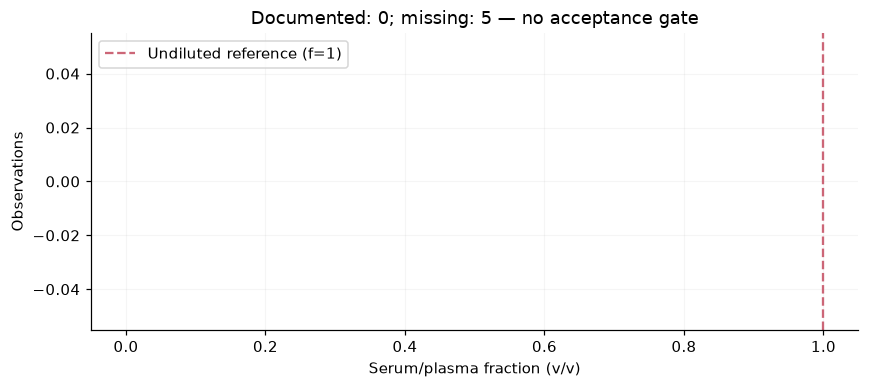

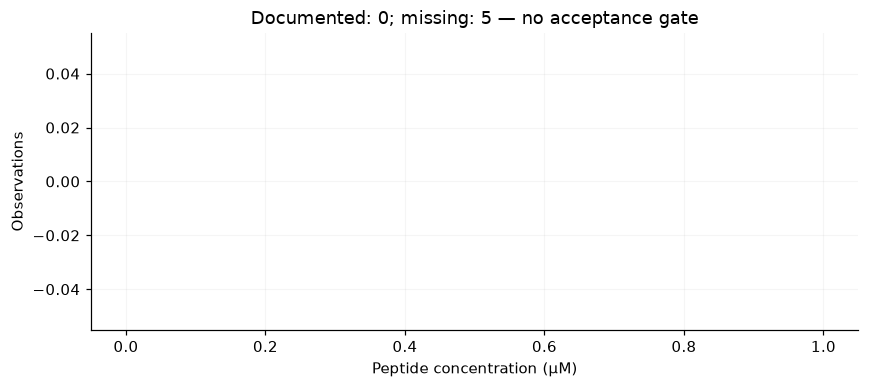

source_record_id,matrix_fraction,peptide_concentration_um,peptide_per_serum_um
"[{'source': 'dramp', 'id': 'stability:DRAMP29853'}]",<NA>,<NA>,<NA>
"[{'source': 'dramp', 'id': 'stability:DRAMP29854'}]",<NA>,<NA>,<NA>
"[{'source': 'dramp', 'id': 'stability:DRAMP29857'}]",<NA>,<NA>,<NA>
"[{'source': 'dramp', 'id': 'stability:DRAMP29858'}]",<NA>,<NA>,<NA>
"[{'source': 'dramp', 'id': 'stability:DRAMP29859'}]",<NA>,<NA>,<NA>


In [4]:
for field, xlabel in [("matrix_fraction","Serum/plasma fraction (v/v)"),("peptide_concentration_um","Peptide concentration (µM)")]:
    fig, ax = plt.subplots(figsize=(9,3.5))
    values=rows[field].dropna().to_numpy(dtype=float)
    ax.hist(values,bins=15,color="#4477AA",edgecolor="white")
    if field=="matrix_fraction": ax.axvline(1,ls="--",color="#CC6677",label="Undiluted reference (f=1)");ax.legend()
    ax.set(xlabel=xlabel,ylabel="Observations",title=f"Documented: {len(values)}; missing: {len(rows)-len(values)} — no acceptance gate")
    figure(fig,"modeling_"+field+".png")
table(rows[["source_record_id","matrix_fraction","peptide_concentration_um","peptide_per_serum_um"]])

## Numerical labels, duration classes and reported uncertainty

**short** <30 min (blue); **medium** 30 min–6 h inclusive (orange); **long** >6 h (green); unresolved (gray). All numerical and class-only observations enter class counts. Numerical histograms use reported points or the explicitly documented CI-midpoint exception only.

Ordinary ranges, censoring and qualitative labels have `half_life_seconds=None`. They retain a class only when justified. A CI midpoint is allowed only for an explicitly documented CI without a reported point and is identified in source remarks. Unspecified ± errors are not renamed SD/CI.

Shared observations carry all contributing sources and IDs. Missing fields can be enriched from verified aliases; known conflicts remain separate. See `normalized/remarks_<source>.md` for label decisions, historical discrepancies and donor records.

In [5]:
table(rows.groupby(["label_availability","half_life_class"],dropna=False).size().rename("observations").reset_index())
table(rows.loc[rows.ci_lower_seconds.notna(),["source_record_id","half_life_seconds","sd_seconds","ci_lower_seconds","ci_upper_seconds","ci_level","replicate_count"]])
print("Normalization decisions:", DATA_ROOT / "normalized" / f"remarks_{DATA_SOURCE}.md")

label_availability,half_life_class,observations
numeric,short,1
unresolved,<NA>,4


source_record_id,half_life_seconds,sd_seconds,ci_lower_seconds,ci_upper_seconds,ci_level,replicate_count


Normalization decisions: /Users/max/Documents/repositories/pep-compass/data/half_time_datasets/normalized/remarks_dramp.md


## Future validation uncertainty — TODO

Missing CI remain null. A later analysis may estimate validation tolerances with a documented model in a separate analysis table. It must not overwrite the reported uncertainty fields.

In [6]:
# TODO (later analysis): implement and validate an uncertainty/tolerance estimator.
# No CI estimation or synthetic interval is applied in this protocol.

## Before / after and common export

Compare the selected condition with all observations accepted by pH/temperature. Every accepted numerical, class-only and unresolved observation is exported. The same 23 columns are used in normalized Parquet, source CSV and final condition CSV.

stage,observations,sequences,numeric,class_only,unresolved
Selected group,5,1,1,0,4
Accepted for condition export,5,1,1,0,4


duration_class,time_interval,all_assigned_records,exact_point_records,bounded_or_non_numeric_records,stage
unresolved,no unique interval,4,0,4,Selected
short,<30 min,1,1,0,Selected
medium,30 min–6 h,0,0,0,Selected
long,>6 h,0,0,0,Selected
unresolved,no unique interval,4,0,4,Accepted
short,<30 min,1,1,0,Accepted
medium,30 min–6 h,0,0,0,Accepted
long,>6 h,0,0,0,Accepted


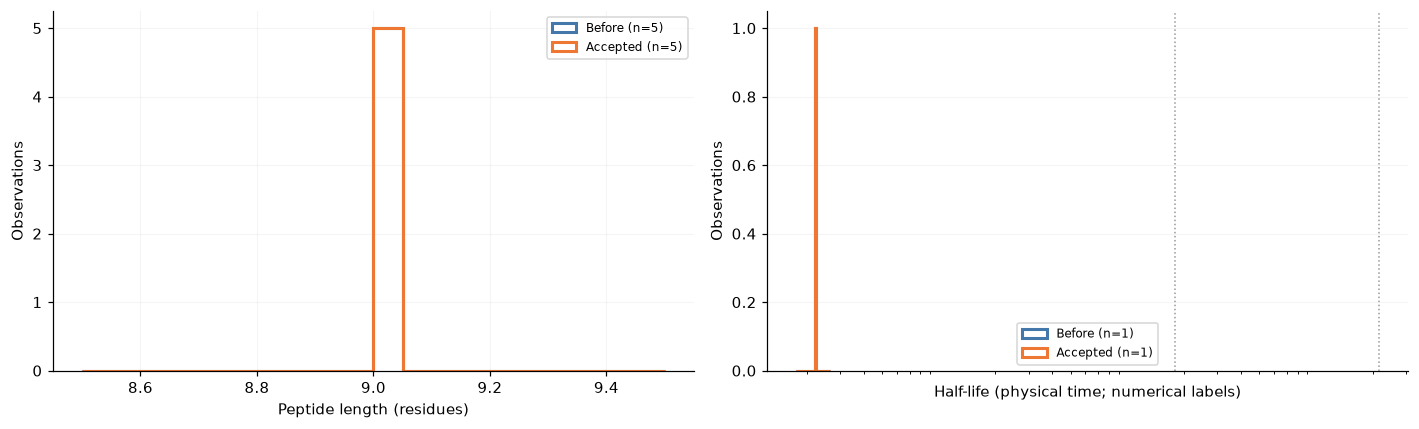

column
source
source_record_id
sequence
sequence_length
chirality
topology
n_terminal_modification
c_terminal_modification
other_modifications
species


Source CSV: /Users/max/Documents/repositories/pep-compass/data/half_time_datasets/processed/human_plasma/sources/dramp.csv
All retained: 5 | numerical: 1 | class-only: 0


In [7]:
retained=rows.loc[rows.aggregation_eligible,CLEAN_COLUMNS].copy()
table(pd.DataFrame([{"stage":"Selected group",**counts(rows)},{"stage":"Accepted for condition export",**counts(retained)}]))
table(pd.concat([duration_summary(rows).assign(stage="Selected"),duration_summary(retained).assign(stage="Accepted")],ignore_index=True))
figure(plot_before_after(rows,retained),"before_after.png")
table(pd.DataFrame({"column":CLEAN_COLUMNS}))
if WRITE_EXPORTS:
    numeric, classes, folder = export_protocol(rows, DATA_ROOT, DATA_SOURCE, CONFIG)
    print("Source CSV:",folder / (DATA_SOURCE+".csv"))
    print("All retained:",len(retained),"| numerical:",len(numeric),"| class-only:",len(classes))
else:
    print("Template: export disabled. Copy this notebook, set source/condition and enable WRITE_EXPORTS.")

## Cavaco baseline audit

Compare source distributions against Cavaco human-serum validation measurements. Shared sequences permit a paired descriptive comparison; full chemistry and conditions must also agree before interpreting it as source agreement. Other conditions are shown as a cross-condition reference and are not pooled with Cavaco.

source,condition,shared_sequences,paired_rows,full_chemistry_matches
dramp,human_plasma,0,0,0


sequence,half_life_seconds_source,half_life_seconds_cavaco,chemistry_match,species_source,matrix_source


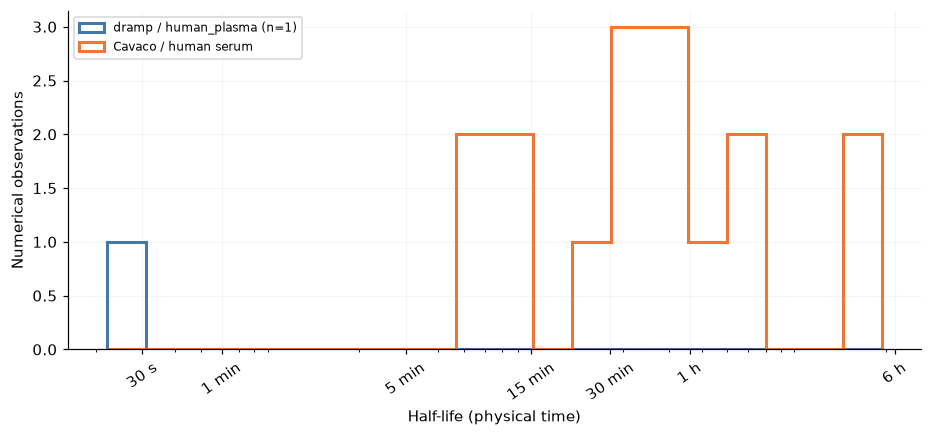

In [8]:
cavaco = all_sources.loc[source_mask(all_sources,"cavaco")]
comparison = retained.merge(cavaco,on="sequence",suffixes=("_source","_cavaco"))
chemistry=["chirality","topology","n_terminal_modification","c_terminal_modification","other_modifications"]
comparison["chemistry_match"] = True
for field in chemistry:
    comparison["chemistry_match"] &= comparison[field+"_source"].notna() & comparison[field+"_source"].eq(comparison[field+"_cavaco"]).fillna(False)
table(pd.DataFrame([{"source":DATA_SOURCE,"condition":CONDITION,"shared_sequences":comparison.sequence.nunique(),"paired_rows":len(comparison),"full_chemistry_matches":int(comparison.chemistry_match.sum())}]))
table(comparison[["sequence","half_life_seconds_source","half_life_seconds_cavaco","chemistry_match","species_source","matrix_source"]])
fig,ax=plt.subplots(figsize=(10,4))
a=retained.half_life_seconds.dropna().to_numpy(dtype=float); b=cavaco.half_life_seconds.dropna().to_numpy(dtype=float)
bins=time_bins(np.r_[a,b],20)
ax.hist(a,bins=bins,histtype="step",lw=2,color="#4477AA",label=f"{DATA_SOURCE} / {CONDITION} (n={len(a)})")
ax.hist(b,bins=bins,histtype="step",lw=2,color="#EE7733",label="Cavaco / human serum")
readable_time_axis(ax);ax.set(xlabel="Half-life (physical time)",ylabel="Numerical observations");ax.legend(fontsize=8)
figure(fig,"cavaco_reference_comparison.png")